# DecodeLabs Data Science Project 3: Customer Segmentation (PCA + K-Means)
**Author:** Al Rafi | **Dataset:** `Dataset_for_Data_Analytics.xlsx` | **Seed:** 42, `n_init=20`

Pipeline: raw data → customer-level features → standardise → PCA → K-Means (Elbow + Silhouette) → profiles → personas.

**Read first:** the data is order-level with 14 columns (not 20+), and cluster structure is weak. The final segments are a practical partition of a continuum, not natural groups. See the README for the full report and robustness checks.

In [1]:
import os, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.stats import chi2_contingency, skew
warnings.filterwarnings("ignore")
SEED, NINIT = 42, 20
rng = np.random.default_rng(SEED)
DATA = next(p for p in ["Dataset_for_Data_Analytics.xlsx", "/mnt/user-data/uploads/Dataset_for_Data_Analytics.xlsx"] if os.path.exists(p))
raw = pd.read_excel(DATA); df = raw.copy()
print("Path:", DATA, "| shape:", raw.shape)
print(raw.dtypes.to_string())

Path: /mnt/user-data/uploads/Dataset_for_Data_Analytics.xlsx | shape: (1200, 14)
OrderID                       str
Date               datetime64[us]
CustomerID                    str
Product                       str
Quantity                    int64
UnitPrice                 float64
ShippingAddress               str
PaymentMethod                 str
OrderStatus                   str
TrackingNumber                str
ItemsInCart                 int64
CouponCode                    str
ReferralSource                str
TotalPrice                float64


## 1. Data audit

In [2]:
print("Missing values:\n", raw.isna().sum()[lambda s: s > 0].to_string(), f"({raw.CouponCode.isna().mean()*100:.2f}% of rows)")
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate OrderID:", raw.OrderID.duplicated().sum(), "| duplicate TrackingNumber:", raw.TrackingNumber.duplicated().sum())
vc = raw.CustomerID.value_counts()
print("Unique customers:", raw.CustomerID.nunique(), "| customers with 2 orders:", (vc > 1).sum())
print("Quantity x UnitPrice != TotalPrice rows:", (abs(raw.Quantity*raw.UnitPrice - raw.TotalPrice) > 0.02).sum(), "| ItemsInCart < Quantity rows:", (raw.ItemsInCart < raw.Quantity).sum())
print("Date range:", raw.Date.min().date(), "to", raw.Date.max().date())
print("Skewness:", raw[["Quantity","UnitPrice","ItemsInCart","TotalPrice"]].apply(skew).round(3).to_dict())
print(raw[["Quantity","UnitPrice","ItemsInCart","TotalPrice"]].describe().round(2).to_string())
print("Order status:", (raw.OrderStatus.value_counts(normalize=True)*100).round(1).to_dict())
df["CouponCode"] = df.CouponCode.fillna("NoCoupon")   # blank = no coupon used

Missing values:
 CouponCode    309 (25.75% of rows)
Duplicate rows: 0 | duplicate OrderID: 0 | duplicate TrackingNumber: 0
Unique customers: 1189 | customers with 2 orders: 11
Quantity x UnitPrice != TotalPrice rows: 0 | ItemsInCart < Quantity rows: 0
Date range: 2023-01-01 to 2025-06-30
Skewness: {'Quantity': 0.028, 'UnitPrice': -0.026, 'ItemsInCart': 0.001, 'TotalPrice': 0.89}
       Quantity  UnitPrice  ItemsInCart  TotalPrice
count   1200.00    1200.00      1200.00     1200.00
mean       2.95     356.41         5.48     1053.97
std        1.41     197.18         2.28      819.86
min        1.00      11.39         1.00       11.39
25%        2.00     186.06         4.00      410.52
50%        3.00     364.21         5.00      823.62
75%        4.00     521.57         7.00     1578.48
max        5.00     699.93        10.00     3456.40
Order status: {'Cancelled': 20.8, 'Returned': 20.6, 'Pending': 19.8, 'Shipped': 19.6, 'Delivered': 19.2}


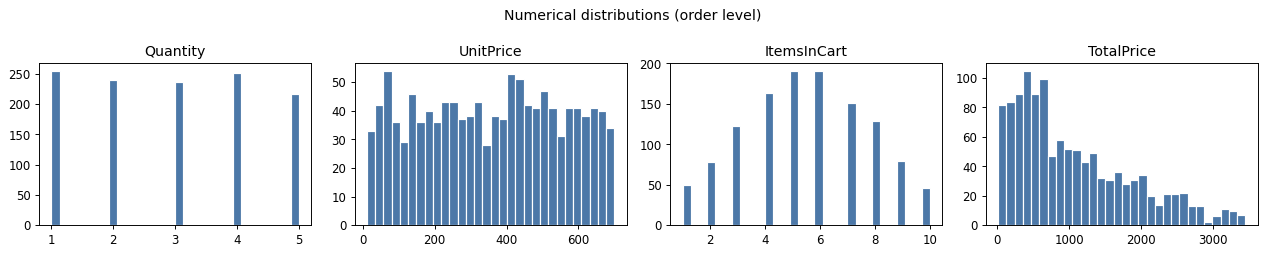

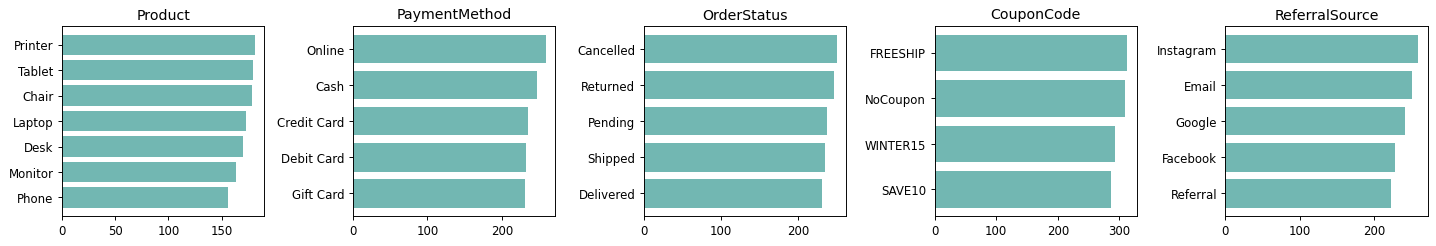

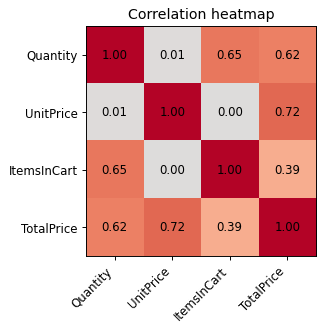

In [3]:
num = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, c in zip(ax, num): a.hist(df[c], bins=30, color="#4C78A8", edgecolor="white"); a.set_title(c)
fig.suptitle("Numerical distributions (order level)"); fig.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 5, figsize=(17, 3))
for a, c in zip(ax, ["Product","PaymentMethod","OrderStatus","CouponCode","ReferralSource"]):
    v = df[c].value_counts(); a.barh(v.index[::-1], v.values[::-1], color="#72B7B2"); a.set_title(c)
fig.tight_layout(); plt.show()
cm = df[num].corr(); fig, a = plt.subplots(figsize=(4.8, 4)); im = a.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
a.set_xticks(range(4)); a.set_yticks(range(4)); a.set_xticklabels(num, rotation=45, ha="right"); a.set_yticklabels(num)
for i in range(4):
    for j in range(4): a.text(j, i, f"{cm.iloc[i,j]:.2f}", ha="center", va="center")
a.set_title("Correlation heatmap"); fig.tight_layout(); plt.show()

**Findings:** no duplicates; only `CouponCode` is missing (blank = no coupon, so filled with `NoCoupon`); `TotalPrice` is exactly `Quantity × UnitPrice` (excluded from clustering); numeric features are near-symmetric (no log transform needed); categories are near-uniform; only about 39% of orders are Delivered or Shipped. The data is order-level, so I aggregate to customers.

## 2. Customer-level features and scaling

In [4]:
SNAP = df.Date.max() + pd.Timedelta(days=1)
df["recency_days"] = (SNAP - df.Date).dt.days
g = df.groupby("CustomerID")
cust = pd.DataFrame({"n_orders": g.size(), "avg_quantity": g.Quantity.mean(), "avg_unit_price": g.UnitPrice.mean(),
                     "avg_items_in_cart": g.ItemsInCart.mean(), "recency_days": g.recency_days.min(), "total_spend": g.TotalPrice.sum()})
cats = {"Product": "prod", "PaymentMethod": "pay", "OrderStatus": "status", "CouponCode": "coupon", "ReferralSource": "ref"}
dums = []
for col, p in cats.items():
    d = pd.get_dummies(df[col], prefix=p).astype(float); d["CustomerID"] = df.CustomerID; dums.append(d.groupby("CustomerID").mean())
cat_df = pd.concat(dums, axis=1)
NUM = ["avg_quantity", "avg_unit_price", "avg_items_in_cart", "recency_days"]
Xn = cust[NUM]; Xf = pd.concat([Xn, cat_df], axis=1)           # Space N (4 features), Space F (30 columns)
print("Customers:", len(cust), "| Space N:", Xn.shape[1], "features | Space F:", Xf.shape[1], "columns")
scaler = StandardScaler().fit(Xn); Zn = scaler.transform(Xn); Zf = StandardScaler().fit_transform(Xf)
print("Scaling check (mean, std):", Zn.mean(0).round(6), Zn.std(0).round(6))

Customers: 1189 | Space N: 4 features | Space F: 30 columns
Scaling check (mean, std): [ 0. -0.  0. -0.] [1. 1. 1. 1.]


## 3. PCA: explained variance

N (4 features): 2 PCs 66.6% | 3 PCs 91.2% | PCs for 90%: 3 | PCs for 95%: 4
F (30 columns): 2 PCs 10.8% | 3 PCs 15.7% | PCs for 90%: 22 | PCs for 95%: 23
Space N explained variance ratios: [0.4138 0.2524 0.2459 0.0879]
                     PC1    PC2    PC3    PC4
avg_quantity       0.702 -0.056 -0.070 -0.706
avg_unit_price     0.018  0.794 -0.607  0.016
avg_items_in_cart  0.704 -0.054 -0.031  0.708
recency_days       0.105  0.603  0.791 -0.023


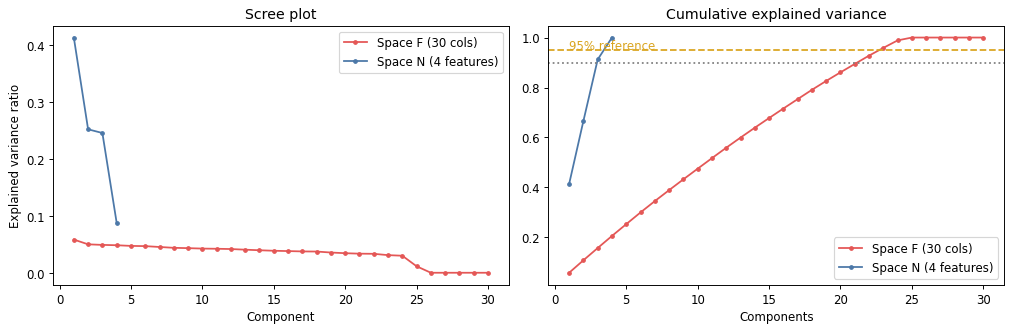

In [5]:
pn, pf = PCA(random_state=SEED).fit(Zn), PCA(random_state=SEED).fit(Zf)
for name, p in [("N (4 features)", pn), ("F (30 columns)", pf)]:
    cum = np.cumsum(p.explained_variance_ratio_)
    print(f"{name}: 2 PCs {cum[1]*100:.1f}% | 3 PCs {cum[2]*100:.1f}% | PCs for 90%: {np.argmax(cum>=.90)+1} | PCs for 95%: {np.argmax(cum>=.95)+1}")
print("Space N explained variance ratios:", pn.explained_variance_ratio_.round(4))
print(pd.DataFrame(pn.components_.T, index=NUM, columns=[f"PC{i+1}" for i in range(4)]).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for p, lab, col in [(pf, "Space F (30 cols)", "#E45756"), (pn, "Space N (4 features)", "#4C78A8")]:
    ev = p.explained_variance_ratio_; k = np.arange(1, len(ev)+1)
    ax[0].plot(k, ev, "o-", ms=3, color=col, label=lab); ax[1].plot(k, np.cumsum(ev), "o-", ms=3, color=col, label=lab)
ax[0].set_title("Scree plot"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio"); ax[0].legend()
ax[1].axhline(.95, ls="--", color="goldenrod"); ax[1].text(1, .955, "95% reference", color="goldenrod")
ax[1].axhline(.90, ls=":", color="grey"); ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Components"); ax[1].legend(loc="lower right")
fig.tight_layout(); plt.show()

**Reading:** in Space F (30 columns) two or three PCs keep only about 11% and 16% of variance, so it cannot be compressed to 2 to 3 dimensions without large loss. In Space N, three PCs keep 91.2%. The "4 or 5 components keep 95%" picture in the course slides does not apply here.

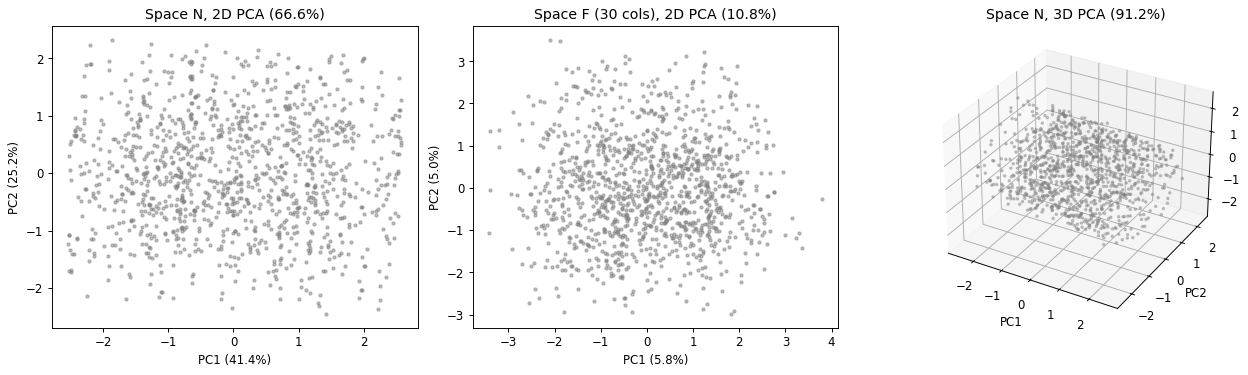

In [6]:
P3 = PCA(3, random_state=SEED).fit_transform(Zn); P2 = P3[:, :2]
Pf = PCA(2, random_state=SEED).fit_transform(Zf)
fig = plt.figure(figsize=(15, 4.5))
a = fig.add_subplot(1, 3, 1); a.scatter(P2[:,0], P2[:,1], s=7, alpha=.5, color="grey"); a.set_title("Space N, 2D PCA (66.6%)"); a.set_xlabel("PC1 (41.4%)"); a.set_ylabel("PC2 (25.2%)")
a = fig.add_subplot(1, 3, 2); a.scatter(Pf[:,0], Pf[:,1], s=7, alpha=.5, color="grey"); a.set_title("Space F (30 cols), 2D PCA (10.8%)"); a.set_xlabel("PC1 (5.8%)"); a.set_ylabel("PC2 (5.0%)")
a = fig.add_subplot(1, 3, 3, projection="3d"); a.scatter(*P3.T, s=4, alpha=.4, color="grey"); a.set_title("Space N, 3D PCA (91.2%)"); a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.set_zlabel("PC3")
fig.tight_layout(); plt.show()

## 4. Elbow Method and Silhouette Score

In [7]:
def sweep(Z, name, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=NINIT, random_state=SEED).fit(Z)
        sz = np.bincount(km.labels_) / len(Z) * 100
        rows.append(dict(space=name, K=k, WCSS=km.inertia_, silhouette=silhouette_score(Z, km.labels_), sizes=" / ".join(f"{s:.0f}%" for s in sz)))
    return pd.DataFrame(rows)
k95 = int(np.argmax(np.cumsum(pf.explained_variance_ratio_) >= .95) + 1)
spaces = {"N 4-D standardised": Zn, "N PCA-3 (91.2%)": P3, "N PCA-2 (66.6%)": P2, "F 30-D standardised": Zf,
          f"F PCA-{k95} (95%)": PCA(k95, random_state=SEED).fit_transform(Zf)}
sw = pd.concat([sweep(Z, n) for n, Z in spaces.items()], ignore_index=True)
print(sw[sw.space == "N PCA-3 (91.2%)"].round(3).to_string(index=False))
def knee(ks, w):
    x, y = np.array(ks, float), np.array(w, float); xn, yn = (x-x.min())/(x.max()-x.min()), (y-y.min())/(y.max()-y.min()); d = (1-yn)-xn
    return int(ks[int(np.argmax(d))]), round(float(d.max()), 3)
print("Chord-distance knee (K, strength):", {n: knee(list(g.K), list(g.WCSS)) for n, g in sw.groupby("space", sort=False)})

          space  K     WCSS  silhouette                                                 sizes
N PCA-3 (91.2%)  2 2922.599       0.288                                             50% / 50%
N PCA-3 (91.2%)  3 2394.588       0.256                                       30% / 40% / 31%
N PCA-3 (91.2%)  4 1940.518       0.270                                 24% / 23% / 26% / 27%
N PCA-3 (91.2%)  5 1659.180       0.268                           19% / 21% / 18% / 22% / 21%
N PCA-3 (91.2%)  6 1422.595       0.275                     17% / 17% / 13% / 18% / 16% / 19%
N PCA-3 (91.2%)  7 1259.091       0.275               13% / 16% / 16% / 11% / 12% / 13% / 18%
N PCA-3 (91.2%)  8 1112.466       0.273         14% / 12% / 13% / 13% / 14% / 10% / 12% / 12%
N PCA-3 (91.2%)  9 1031.171       0.272    14% / 8% / 10% / 12% / 10% / 13% / 11% / 11% / 11%
N PCA-3 (91.2%) 10  956.152       0.269 10% / 10% / 11% / 10% / 11% / 9% / 9% / 12% / 8% / 9%
Chord-distance knee (K, strength): {'N 4-D standardised': (5

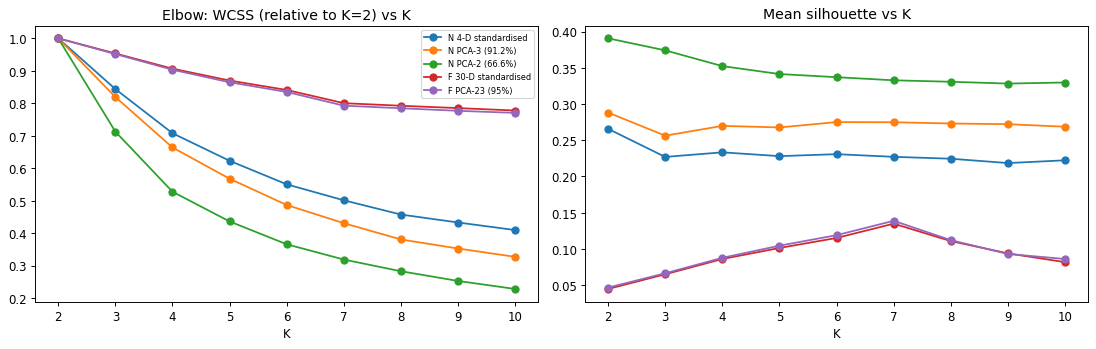

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for n, g in sw.groupby("space", sort=False):
    ax[0].plot(g.K, g.WCSS / g.WCSS.iloc[0], "o-", label=n); ax[1].plot(g.K, g.silhouette, "o-", label=n)
ax[0].set_title("Elbow: WCSS (relative to K=2) vs K"); ax[0].set_xlabel("K"); ax[0].legend(fontsize=7)
ax[1].set_title("Mean silhouette vs K"); ax[1].set_xlabel("K"); fig.tight_layout(); plt.show()

**Space F is an artefact.** Its silhouette peaks at K = 7 and K-Means just recovers the 7 product categories (checked below). Also, silhouette in 2D PCA looks better only because dropping dimensions makes points look closer.

In [9]:
k7 = KMeans(7, n_init=NINIT, random_state=SEED).fit_predict(Zf)
print("ARI between 30-D K=7 clusters and Product:", round(adjusted_rand_score(k7, cust.index.map(df.groupby("CustomerID").Product.first())), 3))
# structure-free baseline: shuffle each original variable (one-hot blocks intact)
def groups(X):
    gp = {}
    for c in X.columns: gp.setdefault(c.split("_")[0] if c.split("_")[0] in cats.values() else c, []).append(c)
    return gp
def null_sil(X, ks=range(2, 11), reps=3):
    out = {k: [] for k in ks}; gp = groups(X)
    for _ in range(reps):
        Xp = X.copy()
        for cols in gp.values(): Xp[cols] = X[cols].values[rng.permutation(len(X))]
        Z = StandardScaler().fit_transform(Xp)
        for k in ks: out[k].append(silhouette_score(Z, KMeans(k, n_init=5, random_state=SEED).fit_predict(Z)))
    return {k: round(float(np.mean(v)), 3) for k, v in out.items()}
nullN = null_sil(Xn); real = sw[sw.space == "N 4-D standardised"].set_index("K").silhouette.round(3).to_dict()
print("Space N 4-D silhouette, real vs shuffled baseline:")
print(pd.DataFrame({"real": real, "shuffled": nullN}).T.to_string())

ARI between 30-D K=7 clusters and Product: 0.99
Space N 4-D silhouette, real vs shuffled baseline:
             2      3      4      5      6      7      8      9      10
real      0.266  0.227  0.233  0.228  0.231  0.227  0.225  0.219  0.222
shuffled  0.186  0.181  0.197  0.204  0.205  0.211  0.220  0.218  0.217


## 5. Choosing representation and K
- **Representation:** PCA-3 keeps 91.2% of variance and satisfies the 2 to 3 dimension requirement. Below I check it reproduces the 4-D solution.
- **K:** no sharp elbow, near-flat silhouette. K = 2 scores highest but is too coarse to act on; K = 4 vs 5 is close. I choose **K = 4** on balanced sizes, better stability than K = 5, and knee agreement in PCA-2. This is a practical choice, not a claim that 4 is the "true" number of clusters.

In [10]:
K = 4
ref = KMeans(K, n_init=NINIT, random_state=SEED).fit_predict(Zn)
comp = []
for name, M in [("4-D", Zn), ("PCA-3", P3), ("PCA-2", P2)]:
    l = KMeans(K, n_init=NINIT, random_state=SEED).fit_predict(M)
    comp.append(dict(space=name, sil_own_space=round(silhouette_score(M, l), 3), sil_in_4D=round(silhouette_score(Zn, l), 3), ARI_vs_4D=round(adjusted_rand_score(ref, l), 3)))
print(pd.DataFrame(comp).to_string(index=False))
# stability of K = 2..8 (bootstrap ARI, 4-D)
def stab(Z, k, B=20):
    base = KMeans(k, n_init=NINIT, random_state=SEED).fit(Z); out = []
    for b in range(B):
        idx = rng.choice(len(Z), len(Z), replace=True); out.append(adjusted_rand_score(base.labels_, KMeans(k, n_init=10, random_state=b).fit(Z[idx]).predict(Z)))
    return round(float(np.mean(out)), 2)
print("Bootstrap ARI by K (4-D):", {k: stab(Zn, k) for k in range(2, 9)})

space  sil_own_space  sil_in_4D  ARI_vs_4D
  4-D          0.233      0.233      1.000
PCA-3          0.270      0.233      0.977
PCA-2          0.352      0.197      0.440
Bootstrap ARI by K (4-D): {2: 0.96, 3: 0.5, 4: 0.75, 5: 0.62, 6: 0.61, 7: 0.68, 8: 0.74}


## 6. Final model (K = 4, PCA-3 space)

In [11]:
km = KMeans(K, n_init=NINIT, random_state=SEED).fit(P3); lab0 = km.labels_
order = pd.Series(cust.avg_unit_price.values).groupby(lab0).mean().sort_values(ascending=False).index.tolist()
remap = {o: n for n, o in enumerate(order)}; lab = np.array([remap[l] for l in lab0]); cent = km.cluster_centers_[order]
sv = silhouette_samples(P3, lab)
print(f"Converged in {km.n_iter_} iterations | inertia {km.inertia_:.1f} | sizes {np.bincount(lab).tolist()}")
print(f"Silhouette: PCA-3 {silhouette_score(P3, lab):.3f} | 4-D {silhouette_score(Zn, lab):.3f} | per cluster {[round(float(sv[lab==c].mean()),3) for c in range(K)]} | negative: {(sv<0).mean()*100:.1f}%")
seed_ari = [adjusted_rand_score(lab0, KMeans(K, n_init=1, random_state=s).fit_predict(P3)) for s in range(30)]
boot = [adjusted_rand_score(lab0, KMeans(K, n_init=10, random_state=b).fit(P3[(i := rng.choice(len(P3), len(P3)))]).predict(P3)) for b in range(40)]
print(f"Single-init seeds ARI mean {np.mean(seed_ari):.2f} (min {np.min(seed_ari):.2f}); bootstrap ARI {np.mean(boot):.2f} +/- {np.std(boot):.2f}")
print("ARI vs 4-D K-Means labels:", round(adjusted_rand_score(lab, ref), 3))

Converged in 11 iterations | inertia 1940.5 | sizes [290, 305, 317, 277]
Silhouette: PCA-3 0.270 | 4-D 0.233 | per cluster [0.273, 0.273, 0.259, 0.276] | negative: 0.3%
Single-init seeds ARI mean 0.72 (min 0.25); bootstrap ARI 0.73 +/- 0.22
ARI vs 4-D K-Means labels: 0.977


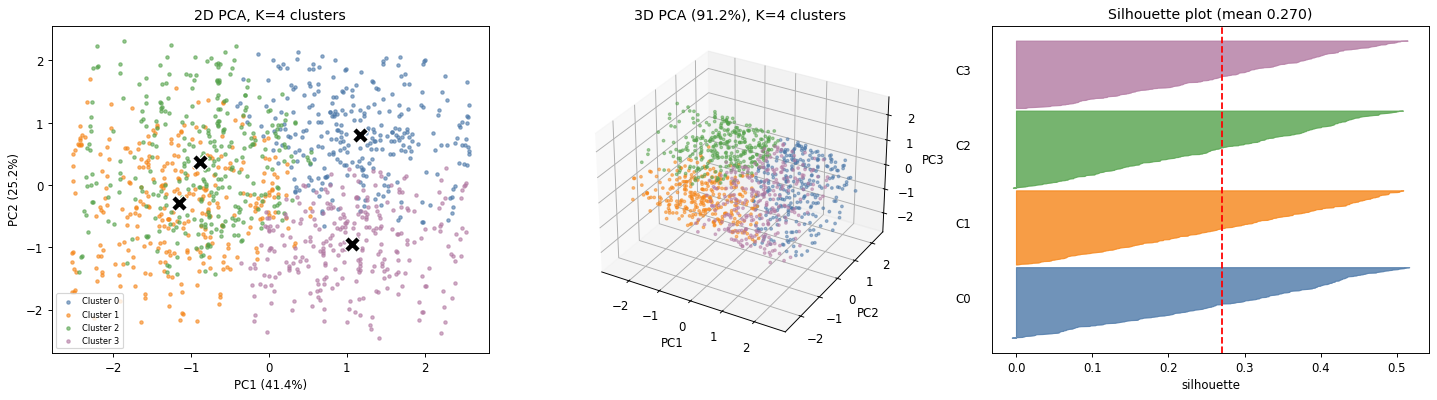

In [12]:
cols = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]; ev = PCA(random_state=SEED).fit(Zn).explained_variance_ratio_
fig = plt.figure(figsize=(17, 4.8))
a = fig.add_subplot(1, 3, 1)
for c in range(K): a.scatter(P2[lab==c,0], P2[lab==c,1], s=8, alpha=.6, color=cols[c], label=f"Cluster {c}")
a.scatter(cent[:,0], cent[:,1], marker="X", s=180, c="black", edgecolor="white"); a.set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); a.set_ylabel(f"PC2 ({ev[1]*100:.1f}%)"); a.legend(fontsize=7); a.set_title("2D PCA, K=4 clusters")
a = fig.add_subplot(1, 3, 2, projection="3d")
for c in range(K): a.scatter(*P3[lab==c].T, s=5, alpha=.5, color=cols[c])
a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.set_zlabel("PC3"); a.set_title("3D PCA (91.2%), K=4 clusters")
a = fig.add_subplot(1, 3, 3); y = 10
for c in range(K):
    v = np.sort(sv[lab==c]); a.fill_betweenx(np.arange(y, y+len(v)), 0, v, color=cols[c], alpha=.8); a.text(-0.08, y+len(v)/2, f"C{c}"); y += len(v)+10
a.axvline(sv.mean(), ls="--", color="red"); a.set_yticks([]); a.set_xlabel("silhouette"); a.set_title(f"Silhouette plot (mean {sv.mean():.3f})")
fig.tight_layout(); plt.show()

## 7. Cluster profiles in original units

In [13]:
cs = cust.join(cat_df); cs["cluster"] = lab
cs["share_coupon_used"] = 1 - cs.coupon_NoCoupon; cs["share_realised"] = cs.status_Delivered + cs.status_Shipped
pc = ["avg_quantity", "avg_unit_price", "avg_items_in_cart", "recency_days", "total_spend", "share_coupon_used", "share_realised"]
prof = cs.groupby("cluster")[pc].mean(); prof.insert(0, "n", cs.groupby("cluster").size()); prof.insert(1, "pct", (prof.n/len(cs)*100).round(1))
prof.loc["ALL"] = [len(cs), 100.0] + cs[pc].mean().tolist()
print("MEANS\n", prof.round(2).to_string())
print("\nMEDIANS (total_spend, recency)\n", cs.groupby("cluster")[["total_spend", "recency_days"]].median().round(1).to_string())
print("\nINDEX vs overall (=100)\n", (prof[pc] / prof.loc["ALL", pc] * 100).round(0).to_string())
print("\nη² (share of feature variance explained by cluster):", {f: round(float(sum((cs.cluster==c).sum()*(cs[cs.cluster==c][f].mean()-cs[f].mean())**2 for c in range(K)) / ((cs[f]-cs[f].mean())**2).sum()), 2) for f in NUM})
rec = pd.DataFrame(scaler.inverse_transform(PCA(3, random_state=SEED).fit(Zn).inverse_transform(cent)), columns=NUM).round(2)
print("\nReconstructed centroids (approximation, PC4 dropped)\n", rec.to_string())

MEANS
               n    pct  avg_quantity  avg_unit_price  avg_items_in_cart  recency_days  total_spend  share_coupon_used  share_realised
cluster                                                                                                                              
0         290.0   24.4          4.12          533.19               7.20        545.29      2195.02               0.74            0.37
1         305.0   25.7          1.87          405.64               3.80        210.02       782.54               0.76            0.42
2         317.0   26.7          1.93          307.45               4.01        682.15       596.23               0.73            0.36
3         277.0   23.3          4.07          174.71               7.25        405.82       723.93               0.74            0.40
ALL      1189.0  100.0          2.95          356.77               5.49        463.28      1063.72               0.74            0.39

MEDIANS (total_spend, recency)
          total_spend  

Chi-square p-values by cluster: {'Product': 0.014, 'PaymentMethod': 0.052, 'OrderStatus': 0.957, 'CouponCode': 0.999, 'ReferralSource': 0.754} (Bonferroni threshold for 5 tests = 0.01)

Realised revenue (Delivered or Shipped)
          orders  gross_value  realised_value  realised_order_rate_%  share_of_realised_%
cluster                                                                                 
0         292.0     636555.3        237872.5                   37.3                 48.7
1         309.0     238674.3         95981.0                   42.1                 19.6
2         319.0     189005.0         71285.5                   36.4                 14.6
3         280.0     200527.3         83620.9                   39.6                 17.1


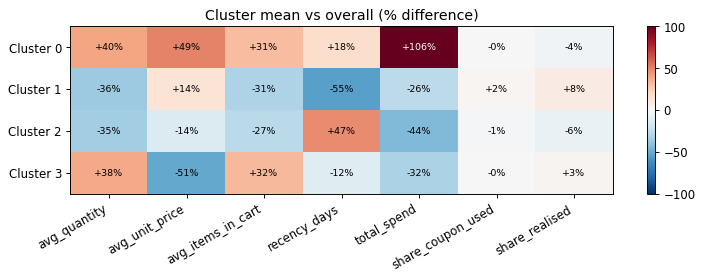

In [14]:
# categorical association (post-hoc; these fields were NOT used for clustering in the final model)
res = {}
for col, p in cats.items():
    dc = [c for c in cs.columns if c.startswith(p + "_")]
    res[col] = round(float(chi2_contingency(pd.DataFrame({c: cs[cs.cluster==c][dc].sum() for c in range(K)}).values)[1]), 3)
print("Chi-square p-values by cluster:", res, "(Bonferroni threshold for 5 tests = 0.01)")
o = raw.merge(pd.Series(lab, index=cust.index, name="cluster"), left_on="CustomerID", right_index=True); o["real"] = o.OrderStatus.isin(["Delivered", "Shipped"])
rv = o.groupby("cluster").apply(lambda g: pd.Series({"orders": len(g), "gross_value": g.TotalPrice.sum(), "realised_value": g.TotalPrice[g.real].sum(), "realised_order_rate_%": 100*g.real.mean()}))
rv["share_of_realised_%"] = 100 * rv.realised_value / rv.realised_value.sum(); print("\nRealised revenue (Delivered or Shipped)\n", rv.round(1).to_string())
H = (prof.loc[range(K), pc] / prof.loc["ALL", pc] * 100 - 100).values
fig, a = plt.subplots(figsize=(9, 3.4)); im = a.imshow(H, cmap="RdBu_r", vmin=-100, vmax=100, aspect="auto")
a.set_xticks(range(len(pc))); a.set_xticklabels(pc, rotation=30, ha="right"); a.set_yticks(range(K)); a.set_yticklabels([f"Cluster {c}" for c in range(K)])
for i in range(K):
    for j in range(len(pc)): a.text(j, i, f"{H[i,j]:+.0f}%", ha="center", va="center", fontsize=8, color="white" if abs(H[i,j]) >= 70 else "black")
a.set_title("Cluster mean vs overall (% difference)"); fig.colorbar(im); fig.tight_layout(); plt.show()

## 8. Sensitivity checks

In [15]:
def fit(M): return KMeans(K, n_init=NINIT, random_state=SEED).fit_predict(M)
rows = [("Final (4 features, PCA-3)", P3), ("Drop items_in_cart", StandardScaler().fit_transform(cust[["avg_quantity", "avg_unit_price", "recency_days"]])),
        ("log1p + standardise", StandardScaler().fit_transform(np.log1p(cust[NUM]))),
        ("Robust scaling (median/IQR)", ((cust[NUM]-cust[NUM].median())/(cust[NUM].quantile(.75)-cust[NUM].quantile(.25))).values),
        ("Unscaled raw features", cust[NUM].values)]
out = []
for n, M in rows:
    l = fit(M); out.append(dict(variant=n, silhouette=round(silhouette_score(M, l), 3), ARI_vs_final=round(adjusted_rand_score(lab, l), 3)))
print(pd.DataFrame(out).to_string(index=False))

                    variant  silhouette  ARI_vs_final
  Final (4 features, PCA-3)       0.270         1.000
         Drop items_in_cart       0.281         0.420
        log1p + standardise       0.300         0.274
Robust scaling (median/IQR)       0.215         0.744
      Unscaled raw features       0.392         0.288


Labels change materially under other preprocessing choices, which supports the conclusion that the segments are a practical partition rather than robust natural groups. Unscaled data gives the highest silhouette only because recency dominates the distance.

## 9. Persona matrix
Names come from the observed profiles above (basket size × price × recency). Actions are hypotheses to A/B test, and the data supports no segment-specific channel claims (coupon, referral, status and payment do not differ across clusters).

| Cluster | Persona | Evidence | Strategy (hypothesis) | KPI | Caveat |
|---|---|---|---|---|---|
| 0 | **Bulk Premium Buyers** | Highest quantity, price and spend; about half of realised value | Bundles and volume offers on premium items; fulfilment reliability | Realised-order rate, average order value | Only about 37% of orders Delivered or Shipped |
| 1 | **Recent Mid-Ticket Light Buyers** | Small baskets, mid-high price, most recent | Basket-building cross-sell | Items per order, 90-day repeat rate | Recency of a single order does not prove loyalty |
| 2 | **Lapsed Light Buyers** (potential lapse risk) | Small baskets, lower price, least recent, lowest spend | Low-cost win-back test with a holdout | Reactivation within 90 days | Lapse rests on recency alone; most customers have one order |
| 3 | **Bulk Budget Buyers** | High quantity at lowest price | Multi-buy bundles | Units per order, margin per order | No margin data |

## 10. Limitations
Weak cluster structure (silhouette 0.23 to 0.27, near the shuffled baseline); one order per customer for 99% of customers; 61% of orders not Delivered or Shipped; quantity and items-in-cart overlap; labels sensitive to preprocessing; probably synthetic data; descriptive only, not causal.